In [ ]:
%pip install torch
%pip install torchvision

#libray imports
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torchvision import datasets, transforms

#seed
#torch.manual_seed(16)

device = ('cuda' if torch.cuda.is_available() else
          'mps' if torch.backends.mps.is_available() else 'cpu')

transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.FashionMNIST('./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST('./data', train=False, download=True, transform=transform)
print(f'FashionMNIST: {len(train_dataset)} train images, {len(test_dataset)} test images')

100%|██████████| 26.4M/26.4M [00:00<00:00, 116MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.75MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 58.1MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.6MB/s]


FashionMNIST: 60000 train images, 10000 test images


In [ ]:
#Settings
N_TRAIN = 0
HIDDEN_UNITS = 256
EPOCHS = 20 #We need to work out if we want all epochs no batches or all batch no epoch or a mix (mini-batch) - may need to increase epochs to allow model to show overfitting better (20 - 30)
BATCH = 128 #keep mini-batch (balance between computation efficient and gradient stability)
LEARNING_RATE = 0.001 #keep
DROPOUT_RATES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
SEED = [16, 31, 9, 92, 2] #keep 5

In [ ]:
#Loading the dataset into device tensors: 10% of the dataset will be used for training

def to_tensor(dataset, index=None):
    images, labels = (dataset.data, dataset.targets) if index is None else (dataset.data[index], dataset.targets[index])
    X = images.float().div(255).view(-1,784)
    return X.to(device), labels.to(device)

#generator = torch.Generator().manual_seed(16)
def random_sample(train_dataset, test_dataset):
    order = torch.randperm(len(train_dataset))[:N_TRAIN]
    x_train, y_train = to_tensor(train_dataset, order)
    x_test, y_test = to_tensor(test_dataset)
    print(f"device {device} | Training images: {tuple(x_train.shape)} | Testing images: {tuple(x_test.shape)}")
    #print(f"Training images: {x_train.shape}")
    #print(f"Training labels: {y_train.shape}")
    #print(f"Testing images: {x_test.shape}")
    #print(f"Testing labels: {y_test.shape}")
    return x_train, x_test, y_train, y_test

In [ ]:
#Making and training the model

#Why did we choose 2 hidden layers? we could change this ..., standardise this ... or explain why 2 is the best option.
def make_model(dropout_rate):
    return torch.nn.Sequential(
        torch.nn.Linear(784, HIDDEN_UNITS), torch.nn.ReLU(), torch.nn.Dropout(dropout_rate),
        torch.nn.Linear(HIDDEN_UNITS, HIDDEN_UNITS), torch.nn.ReLU(), torch.nn.Dropout(dropout_rate),
        torch.nn.Linear(HIDDEN_UNITS, 10) #There are only 10 types of clothing class in fashionMNIST.
    ).to(device)

@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    return(model(X).argmax(1) == y).float().mean().item()

@torch.no_grad()
def calculate_loss(model, X, y):
    model.eval()
    loss_function = nn.CrossEntropyLoss()
    return loss_function(model(X), y).item()

def train(model, x_train, y_train, x_test, y_test, seed, verbose=True):
    random_generator = torch.Generator(device="cpu").manual_seed(seed)
    adam_opt = torch.optim.Adam(model.parameters(), lr = LEARNING_RATE)
    loss_function = nn.CrossEntropyLoss()
    results = {"train": [],
               "test": [],
               "train_loss": [],
               "test_loss": []}
    for ep in range(EPOCHS):
        model.train()
        shuffle = torch.randperm(len(x_train), generator=random_generator).to(device)
        for i in range(0, len(x_train), BATCH):
            index = shuffle[i:i + BATCH]
            adam_opt.zero_grad()
            loss = loss_function(model(x_train[index]), y_train[index])
            loss.backward()
            adam_opt.step()
        results["train"].append(accuracy(model, x_train, y_train))
        results["test"].append(accuracy(model, x_test, y_test))
        results["train_loss"].append(calculate_loss(model, x_train, y_train))
        results["test_loss"].append(calculate_loss(model, x_test, y_test))
        if verbose and (ep + 1) % 10  ==0:
            print(
                f"epoch {ep + 1} | "
                f"Training Accuracy: {results['train'][-1]:.4f} | "
                f"Testing Accuracy: {results['test'][-1]:.4f} | "
                f"Training loss: {results['train_loss'][-1]:.4f} | "
                f"Testing Loss: {results['test_loss'][-1]:.4f}"

            )
    return results

In [ ]:
#Run with varying dropout
def dropout_experiment(seed):
    models = {}
    results = {}
    x_train, x_test, y_train, y_test = random_sample(train_dataset, test_dataset)

    for r in DROPOUT_RATES:
        models[r] = make_model(r)
        results[r] = train(models[r], x_train, y_train, x_test, y_test, seed)

    print(f"{'Dropout Rate'} {'Training Accuracy'} {'Test Accuracy'} {'Difference'} {'Training Loss'} {'Testing Loss'}")
    for r in DROPOUT_RATES:
        train_data = results[r]["train"][-1]
        test_data = results[r]["test"][-1]
        train_loss = results[r]["train_loss"][-1]
        test_loss = results[r]["test_loss"][-1]
        print(f"{r:12.2f} {train_data:17.4f} {test_data:13.4f} {train_data-test_data:10.4f} {train_loss:12.4f} {test_loss:13.4f}")

    return results

In [ ]:
def plot_test_accuracy(results):
    percents = sorted(results.keys())
    plt.figure(figsize=(10,6))
    for dropout in DROPOUT_RATES:
        means = []
        stds = []
        for percent in percents:
            seed_accuracies = []
            for seed in results[percent]:
                seed_accuracies.append(results[percent][seed][dropout]["test"][-1])
            means.append(np.mean(seed_accuracies))
            stds.append(np.std(seed_accuracies))

        plt.errorbar(
            [p * 100 for p in percents],
            means,
            yerr = stds,
            marker = "o",
            capsize = 4,
            label = f"Dropout {dropout}"
        )
    plt.xlabel("Training data (%)")
    plt.ylabel("Test Accuracy")
    plt.title("Test Accuracy vs Training Set Size")
    plt.legend()
    plt.grid(True, alpha = 0.3)
    plt.tight_layout()
    plt.show()


In [ ]:
def plot_generalisation_gap(results):
    percents = sorted(results.keys())
    plt.figure(figsize=(10,6))
    for dropout in DROPOUT_RATES:
        means = []
        stds = []
        for percent in percents:
            gaps = []
            for seed in results[percent]:
                train_acc = results[percent][seed][dropout]["train"][-1]
                test_acc = results[percent][seed][dropout]["test"][-1]
                gaps.append(train_acc - test_acc)
            means.append(np.mean(gaps))
            stds.append(np.std(gaps))

        plt.errorbar(
            [p * 100 for p in percents],
            means,
            yerr = stds,
            marker = "o",
            capsize = 4,
            label = f"Dropout {dropout}"
        )
    plt.xlabel("Training data (%)")
    plt.ylabel("Generalisation Gap")
    plt.title("Generalisation Gap vs Training Set Size")
    plt.legend()
    plt.grid(True, alpha = 0.3)
    plt.tight_layout()
    plt.show()

Training data percentage: 2.5%


Seed: 16
device cuda | Training images: (1500, 784) | Testing images: (10000, 784)
epoch 10 | Training Accuracy: 0.8707 | Testing Accuracy: 0.7893 | Training loss: 0.3942 | Testing Loss: 0.6043
epoch 20 | Training Accuracy: 0.9227 | Testing Accuracy: 0.8014 | Training loss: 0.2201 | Testing Loss: 0.6279
epoch 10 | Training Accuracy: 0.8527 | Testing Accuracy: 0.7933 | Training loss: 0.4190 | Testing Loss: 0.6020
epoch 20 | Training Accuracy: 0.9173 | Testing Accuracy: 0.8009 | Training loss: 0.2413 | Testing Loss: 0.6067
epoch 10 | Training Accuracy: 0.8707 | Testing Accuracy: 0.7989 | Training loss: 0.4021 | Testing Loss: 0.5786
epoch 20 | Training Accuracy: 0.9213 | Testing Accuracy: 0.8055 | Training loss: 0.2245 | Testing Loss: 0.5991
epoch 10 | Training Accuracy: 0.8533 | Testing Accuracy: 0.7969 | Training loss: 0.4334 | Testing Loss: 0.5806
epoch 20 | Training Accuracy: 0.9100 | Testing Accuracy: 0.8104 | Training loss: 0.2526 | Testing Loss: 0.5

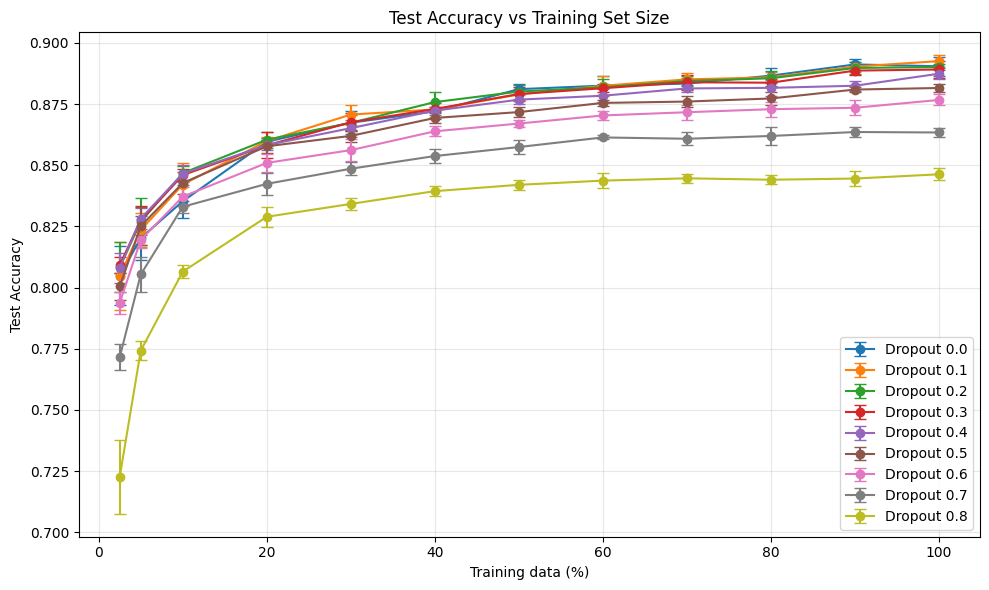

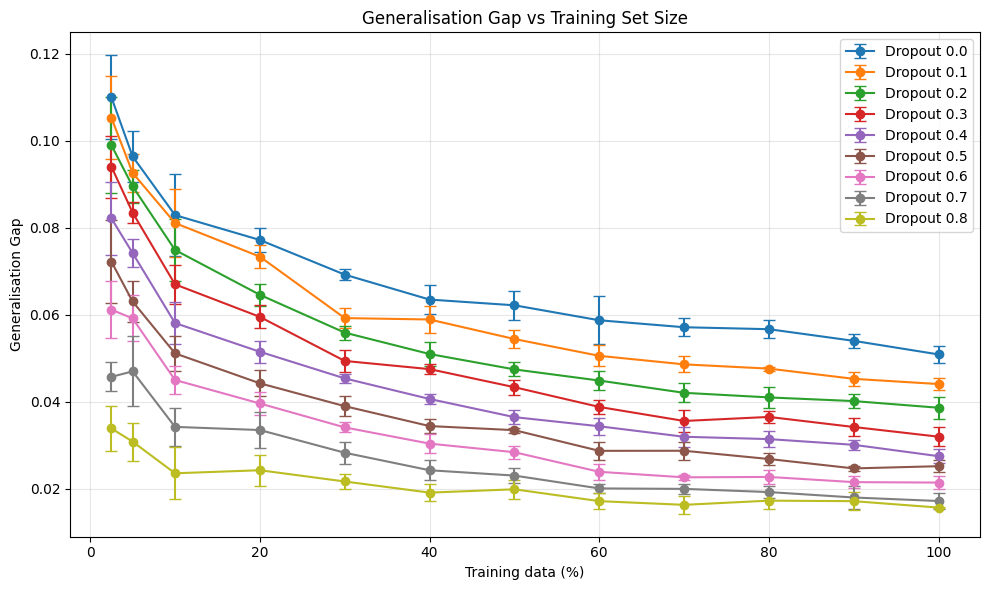

In [ ]:
def main():
    global N_TRAIN
    full_results = {0.025:{}, 0.05:{}, 0.1:{},
                    0.2:{}, 0.3:{}, 0.4:{},
                    0.5:{}, 0.6:{}, 0.7:{},
                    0.8:{}, 0.9:{}, 1:{}}
    for percent in full_results:
        print(f"Training data percentage: {percent * 100}%\n")
        for i in SEED:
            print(f"\nSeed: {i}")
            N_TRAIN = int(len(train_dataset) * percent)
            full_results[percent][i] = dropout_experiment(i)

    plot_test_accuracy(full_results)
    plot_generalisation_gap(full_results)

main()